
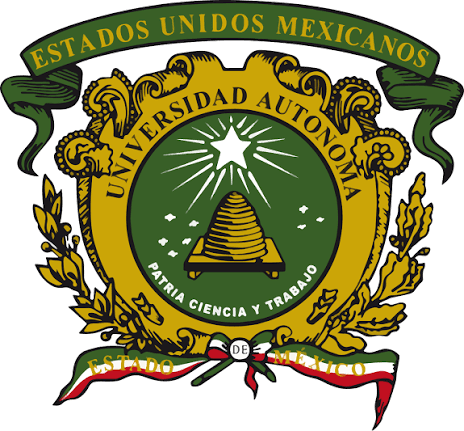

In [26]:
from pathlib import Path
from base64 import b64encode
from IPython.display import HTML, display

# Edita aquí los datos de la portada.
campus = "Centro Universitario UAEM Zumpango"
semestre = "5.º semestre"
turno = "Turno matutino"
asignatura = "Investigación de Operaciones"
practica = "Práctica 1 · Árbol de expansión mínima"
proyecto = "Diseño de una red de fibra óptica"

integrantes = [
    "Daniela Cacahuatitla García",
    "Alexander Garcia Gonzales",
    "Rafael Mimbrera Moreno"
]

# Insertar el escudo dentro de la portada.
archivo_escudo = Path("escudo_uaem.png")

if archivo_escudo.is_file():
    imagen = b64encode(archivo_escudo.read_bytes()).decode("ascii")
    escudo = (
        f'<img src="data:image/png;base64,{imagen}" '
        'alt="Escudo de la UAEMéx" '
        'style="width:120px; max-width:27%; height:auto;">'
    )
else:
    escudo = '<div style="color:#2e501d; font-weight:bold;">UAEMéx</div>'

nombres = "<br>".join(integrantes)

portada = f"""
<div style="
    box-sizing:border-box;
    position:relative;
    max-width:760px;
    min-height:790px;
    margin:16px auto;
    padding:52px 35px 50px 65px;
    background:#ffffff;
    color:#171717;
    font-family:Arial, sans-serif;
    text-align:center;
    border:1px solid #dddddd;
">
    <div style="
        position:absolute; top:0; bottom:0; left:0;
        width:30px; background:#2e501d;
        border-right:10px solid #aa8b30;
    "></div>

    <div style="
        display:flex; align-items:center; justify-content:center;
        gap:20px; margin-bottom:45px;
    ">
        {escudo}
        <div style="font-size:20px; font-weight:bold; line-height:1.35;">
            Universidad Autónoma del Estado de México
        </div>
    </div>

    <div style="font-size:17px; font-weight:bold; color:#2e501d;">
        {campus.upper()}
    </div>

    <div style="margin-top:36px; font-size:16px; line-height:1.8;">
        <strong>{semestre}</strong><br>
        {turno}
    </div>

    <div style="margin-top:32px; font-size:18px; font-weight:bold;">
        {asignatura}
    </div>

    <h1 style="margin:14px 0 8px; font-size:28px; color:#2e501d;">
        {practica}
    </h1>

    <div style="font-size:17px;">{proyecto}</div>

    <div style="margin-top:44px; font-size:16px; line-height:1.8;">
        <strong>Integrantes</strong><br>
        {nombres}
    </div>
</div>
"""

display(HTML(portada))

## Diseño de una red de fibra óptica

### Planteamiento del problema

El Centro Universitario UAEM Zumpango desea instalar una red de fibra óptica para conectar ocho áreas del campus. Para planear el cableado, se consideran once conexiones posibles entre distintas áreas. Cada conexión requiere una cantidad diferente de cable, por lo que se busca elegir cuáles instalar para comunicar las ocho áreas utilizando la menor longitud total posible.

Para representar el problema se utiliza un grafo no dirigido. Cada nodo representa un área del centro universitario, cada enlace representa una conexión que podría instalarse y el peso de cada enlace indica la cantidad de cable necesaria, medida en metros. Las distancias son hipotéticas y se asignaron para esta práctica.

| Nodo | Área del centro universitario |
|---|---|
| A | Edificio administrativo |
| B | Biblioteca |
| C | Laboratorio de cómputo |
| D | Control escolar |
| E | Aulas |
| F | Sala de profesores |
| G | Auditorio |
| H | Cafetería |

Por ejemplo, el enlace A–B tiene un peso de 10 metros. Si se selecciona esta conexión, se necesitan 10 metros de cable para unir el edificio administrativo con la biblioteca. A partir de los once enlaces propuestos, se debe determinar qué combinación permite que las ocho áreas queden comunicadas, ya sea directamente o a través de otras áreas.

### Objetivo

Encontrar un conjunto de siete enlaces que conecte las ocho áreas sin formar ciclos y que minimice la suma de las longitudes de cable. Esta solución se conoce como árbol de expansión mínima.

Para obtenerlo se aplicará el algoritmo de Kruskal. Primero se ordenarán los enlaces de menor a mayor longitud. Después se revisarán uno por uno y se agregará cada enlace que conecte dos grupos que todavía estén separados. Al terminar, se sumarán los pesos de los enlaces seleccionados para determinar cuántos metros de cable se necesitan.

In [24]:
print("Práctica 1: algoritmo de Kruskal")

Práctica 1: algoritmo de Kruskal


## Importación de bibliotecas
Usaremos NetworkX para construir la red y Matplotlib para dibujarla.

In [5]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

print("Bibliotecas cargadas correctamente")

Bibliotecas cargadas correctamente


## Definición de la red

Cada nodo, de la A a la H, representa un área del centro universitario.
Cada enlace indica una conexión posible y su peso representa la longitud
estimada de cable en metros. Las distancias son hipotéticas.

In [6]:
enlaces = [
    ("A", "B", 10), ("B", "C", 12), ("A", "C", 14),
    ("A", "D", 15), ("D", "E", 18), ("B", "E", 19),
    ("C", "F", 20), ("E", "F", 22), ("E", "G", 24),
    ("F", "H", 28), ("G", "H", 30)
]

red = nx.Graph()
red.add_nodes_from("ABCDEFGH")
red.add_weighted_edges_from(enlaces)

print("Nodos:", red.number_of_nodes())
print("Enlaces posibles:", red.number_of_edges())

Nodos: 8
Enlaces posibles: 11


## Gráfica de la red original

La gráfica muestra las ocho áreas del centro universitario y sus
once conexiones posibles. El número sobre cada línea indica cuántos
metros de cable se necesitan para conectar esas dos áreas.

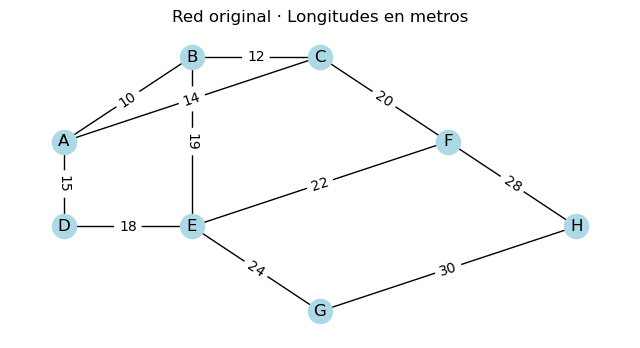

In [7]:
posiciones = {
    "A": (0, 1), "B": (1, 2), "C": (2, 2), "D": (0, 0),
    "E": (1, 0), "F": (3, 1), "G": (2, -1), "H": (4, 0)
}

pesos = nx.get_edge_attributes(red, "weight")

plt.figure(figsize=(8, 4))
nx.draw_networkx(red, posiciones, node_color="lightblue")
nx.draw_networkx_edge_labels(red, posiciones, edge_labels=pesos)
plt.title("Red original · Longitudes en metros")
plt.axis("off")
plt.show()

## Kruskal: paso 1

Ordenamos los enlaces de menor a mayor longitud. El primero es A–B,
con 10 metros. Como A y B aún no están conectados, agregar este enlace
no forma un ciclo. La longitud acumulada es de 10 metros.

Enlace seleccionado: A–B
Longitud acumulada: 10 m


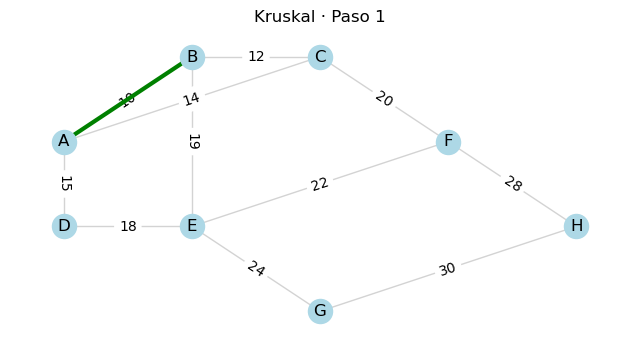

In [8]:
ordenados = sorted(enlaces, key=lambda enlace: enlace[2])

arbol = nx.Graph()
arbol.add_nodes_from(red.nodes)

origen, destino, longitud = ordenados[0]
arbol.add_edge(origen, destino, weight=longitud)

print(f"Enlace seleccionado: {origen}–{destino}")
print(f"Longitud acumulada: {longitud} m")

plt.figure(figsize=(8, 4))
nx.draw_networkx(red, posiciones, node_color="lightblue", edge_color="lightgray")
nx.draw_networkx_edge_labels(red, posiciones, edge_labels=pesos)
nx.draw_networkx_edges(
    arbol, posiciones, edge_color="green", width=3
)
plt.title("Kruskal · Paso 1")
plt.axis("off")
plt.show()

## Kruskal: paso 2

Evaluamos el enlace B–C, de 12 metros. Como C todavía no está
conectado con B, agregamos el enlace. Ahora A, B y C quedan
conectados y la longitud acumulada es de 22 metros.

Enlace seleccionado: B–C
Longitud acumulada: 22 m


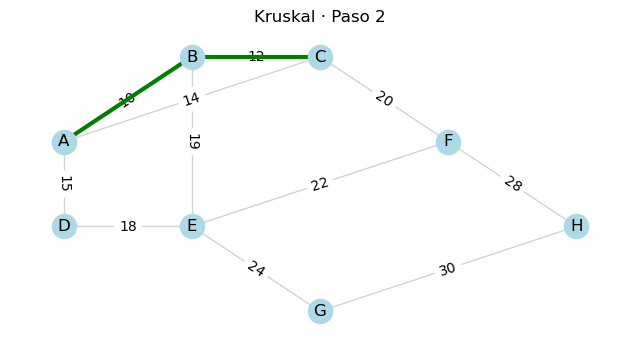

In [9]:
origen, destino, longitud = ordenados[1]
arbol.add_edge(origen, destino, weight=longitud)

total = arbol.size(weight="weight")
print(f"Enlace seleccionado: {origen}–{destino}")
print(f"Longitud acumulada: {total:g} m")

plt.figure(figsize=(8, 4))
nx.draw_networkx(red, posiciones, node_color="lightblue", edge_color="lightgray")
nx.draw_networkx_edge_labels(red, posiciones, edge_labels=pesos)
nx.draw_networkx_edges(arbol, posiciones, edge_color="green", width=3)
plt.title("Kruskal · Paso 2")
plt.axis("off")
plt.show()

In [29]:
def paso_kruskal(numero):
    parcial = nx.Graph()
    parcial.add_nodes_from(red.nodes)

    for origen, destino, longitud in ordenados[:numero]:
        rechazado = nx.has_path(parcial, origen, destino)
        if not rechazado:
            parcial.add_edge(origen, destino, weight=longitud)

    total = parcial.size(weight="weight")
    print(f"Enlace evaluado: {origen}–{destino} ({longitud} m)")

    if rechazado:
        camino = nx.shortest_path(parcial, origen, destino)
        print("Se descarta porque ya existe el camino", "–".join(camino))
    else:
        print("Se agrega al árbol.")

    print(f"Longitud acumulada: {total:g} m")

    plt.figure(figsize=(8, 4))
    nx.draw_networkx(
        red, posiciones, node_color="lightblue", edge_color="lightgray"
    )
    nx.draw_networkx_edges(
        parcial, posiciones, edge_color="green", width=3
    )

    if rechazado:
        nx.draw_networkx_edges(
            red, posiciones, edgelist=[(origen, destino)],
            edge_color="red", style="dashed", width=3
        )

    nx.draw_networkx_edge_labels(red, posiciones, edge_labels=pesos)
    plt.title(f"Kruskal · Paso {numero} · {total:g} m acumulados")
    plt.axis("off")
    plt.show()

    return parcial

## Kruskal: paso 3

Evaluamos el enlace A–C, de 14 m. Lo descartamos porque A y C ya están conectados por el camino A–B–C. Si agregáramos A–C, se formaría un ciclo. El total sigue en 22 m.

Enlace evaluado: A–C (14 m)
Se descarta porque ya existe el camino A–B–C
Longitud acumulada: 22 m


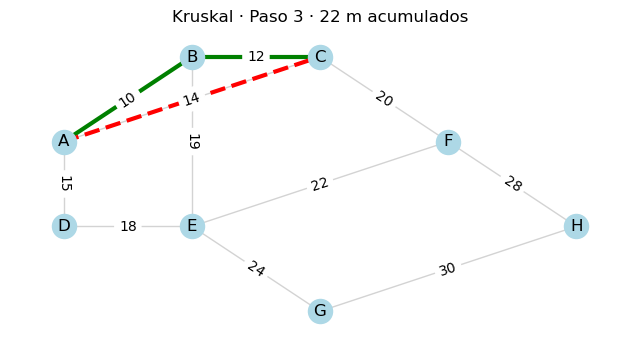

In [30]:
arbol = paso_kruskal(3)

## Kruskal: paso 4

Agregamos el enlace A–D, de 15 m. El nodo D estaba aislado, así que podemos unirlo al grupo de A, B y C sin formar un ciclo. El total aumenta a 37 m.

Enlace evaluado: A–D (15 m)
Se agrega al árbol.
Longitud acumulada: 37 m


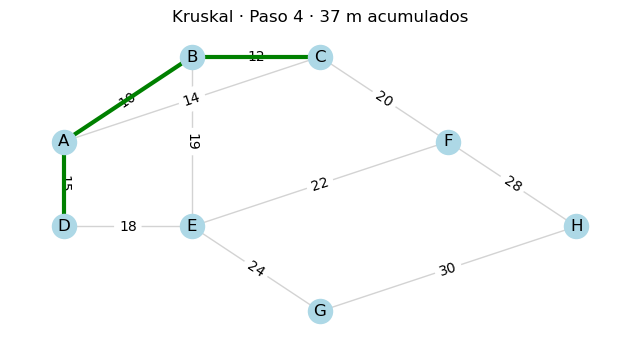

In [16]:
arbol = paso_kruskal(4)

## Kruskal: paso 5

Agregamos el enlace D–E, de 18 m. El nodo E queda conectado al grupo a través de D. La longitud acumulada es de 55 m.

Enlace evaluado: D–E (18 m)
Se agrega al árbol.
Longitud acumulada: 55 m


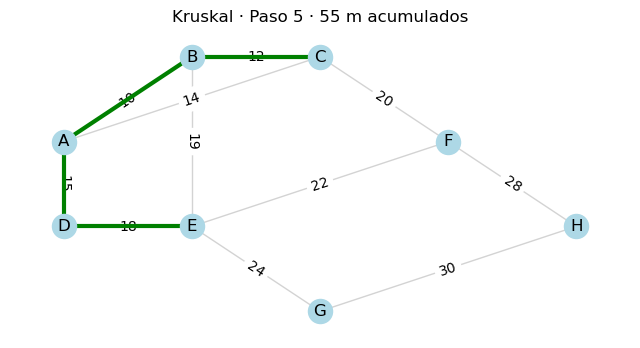

In [17]:
arbol = paso_kruskal(5)

## Kruskal: paso 6

Evaluamos el enlace B–E, de 19 m. Lo descartamos porque B y E ya están conectados por el camino B–A–D–E. El total sigue en 55 m.

Enlace evaluado: B–E (19 m)
Se descarta porque ya existe el camino B–A–D–E
Longitud acumulada: 55 m


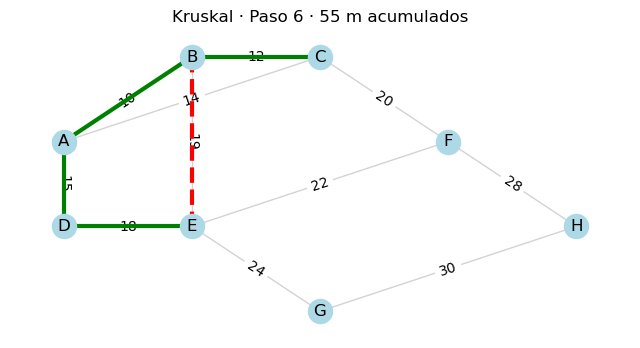

In [18]:
arbol = paso_kruskal(6)

## Kruskal: paso 7

Agregamos el enlace C–F, de 20 m. El nodo F estaba aislado y se incorpora al grupo a través de C. La longitud acumulada es de 75 m.

Enlace evaluado: C–F (20 m)
Se agrega al árbol.
Longitud acumulada: 75 m


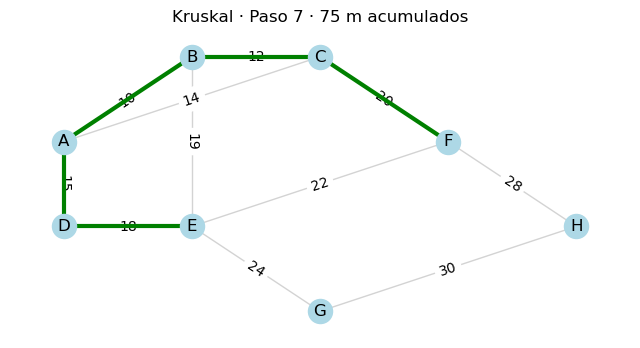

In [19]:
arbol = paso_kruskal(7)

## Kruskal: paso 8

Evaluamos el enlace E–F, de 22 m. Lo descartamos porque E y F ya están conectados por el camino E–D–A–B–C–F. El total sigue en 75 m.

Enlace evaluado: E–F (22 m)
Se descarta porque ya existe el camino E–D–A–B–C–F
Longitud acumulada: 75 m


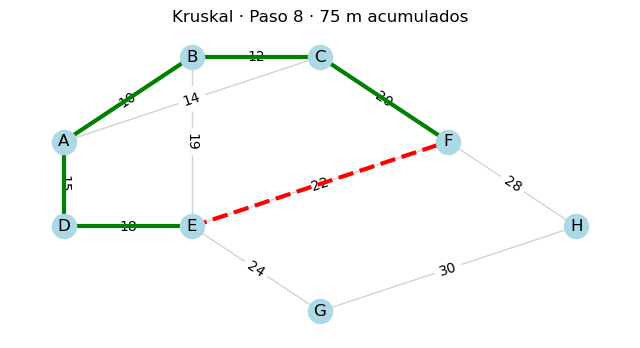

In [20]:
arbol = paso_kruskal(8)

## Kruskal: paso 9

Agregamos el enlace E–G, de 24 m. El nodo G queda conectado a través de E. La longitud acumulada es de 99 m y solo queda H sin conectar.

Enlace evaluado: E–G (24 m)
Se agrega al árbol.
Longitud acumulada: 99 m


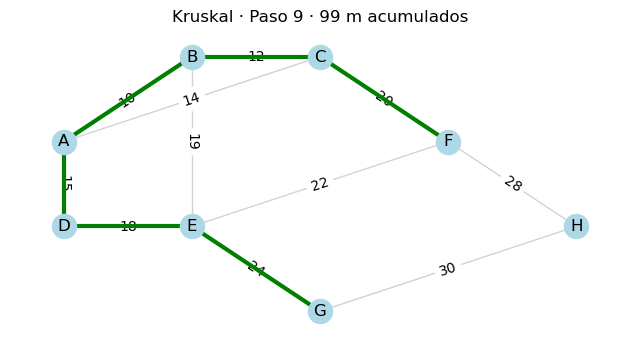

In [21]:
arbol = paso_kruskal(9)

## Evaluación de los enlaces restantes

Kruskal revisa los enlaces de menor a mayor longitud. Si los extremos
de un enlace ya están conectados por un camino, agregarlo formaría un
ciclo y se descarta. Si están separados, se agrega al árbol.

In [11]:
def paso_kruskal(numero):
    parcial = nx.Graph()
    parcial.add_nodes_from(red.nodes)

    for origen, destino, longitud in ordenados[:numero]:
        rechazado = nx.has_path(parcial, origen, destino)
        if not rechazado:
            parcial.add_edge(origen, destino, weight=longitud)

    enlace = f"{origen}–{destino}"
    total = parcial.size(weight="weight")

    print(f"Enlace evaluado: {enlace} ({longitud} m)")
    if rechazado:
        camino = nx.shortest_path(parcial, origen, destino)
        print("Se descarta porque ya existe el camino", "–".join(camino))
    else:
        print("Se agrega al árbol.")
    print(f"Longitud acumulada: {total:g} m")

    plt.figure(figsize=(8, 4))
    nx.draw_networkx(
        red, posiciones, node_color="lightblue", edge_color="lightgray"
    )
    nx.draw_networkx_edge_labels(red, posiciones, edge_labels=pesos)
    nx.draw_networkx_edges(
        parcial, posiciones, edge_color="green", width=3
    )
    if rechazado:
        nx.draw_networkx_edges(
            red, posiciones, edgelist=[(origen, destino)],
            edge_color="red", style="dashed", width=3
        )

    plt.title(f"Kruskal · Paso {numero} · {total:g} m acumulados")
    plt.axis("off")
    plt.show()

    return parcial

## Kruskal: paso 10

Agregamos el enlace F–H, de 28 m. H era el último nodo aislado. Ahora tenemos los ocho nodos conectados con siete enlaces y una longitud total de 127 m. El algoritmo termina en este punto, por lo que el enlace G–H, de 30 m, queda sin evaluar.

Enlace evaluado: F–H (28 m)
Se agrega al árbol.
Longitud acumulada: 127 m


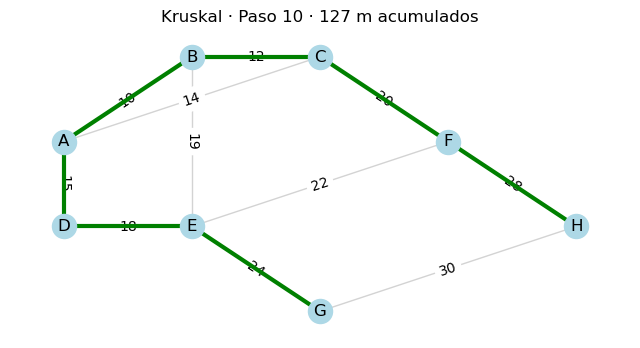

In [13]:
arbol = paso_kruskal(10)

## Árbol de expansión mínima

La figura final muestra los siete enlaces seleccionados. Verificamos que
la red conecta las ocho áreas sin ciclos y que su longitud coincide con
el resultado de la función de árbol mínimo de NetworkX.

Áreas conectadas: 8
Enlaces seleccionados: 7
Longitud mínima total: 127 m


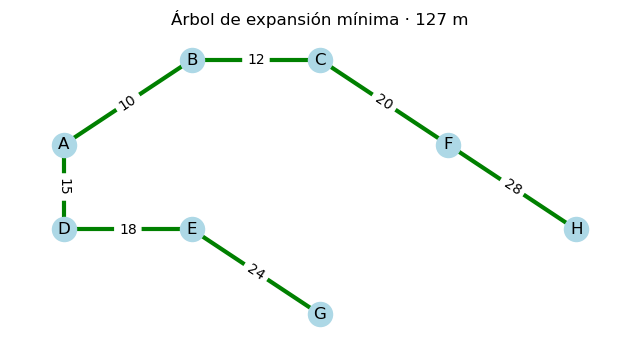

In [14]:
total = arbol.size(weight="weight")
referencia = nx.minimum_spanning_tree(red, weight="weight")

assert nx.is_tree(arbol)
assert total == referencia.size(weight="weight")

print("Áreas conectadas:", arbol.number_of_nodes())
print("Enlaces seleccionados:", arbol.number_of_edges())
print(f"Longitud mínima total: {total:g} m")

plt.figure(figsize=(8, 4))
nx.draw_networkx(
    arbol, posiciones, node_color="lightblue", edge_color="green", width=3
)
nx.draw_networkx_edge_labels(
    arbol, posiciones, edge_labels=nx.get_edge_attributes(arbol, "weight")
)
plt.title("Árbol de expansión mínima · 127 m")
plt.axis("off")
plt.show()